In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

sns.set_theme(style="whitegrid")

df = pd.read_csv("../data/processed/cleaned_data.csv")

print(df.shape)
df.head()

(10000, 12)


,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


In [2]:
print(df["Machine failure"].value_counts())

print(
    df["Machine failure"].value_counts(normalize=True) * 100
)

Machine failure
0    9661
1     339
Name: count, dtype: int64
Machine failure
0    96.61
1     3.39
Name: proportion, dtype: float64


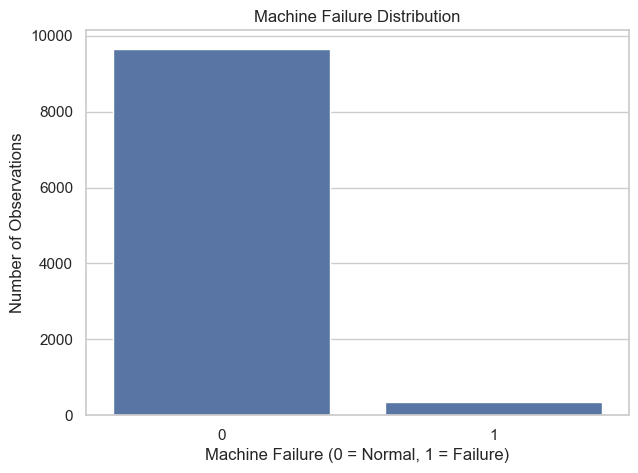

In [5]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="Machine failure"
)

plt.title("Machine Failure Distribution")
plt.xlabel("Machine Failure (0 = Normal, 1 = Failure)")
plt.ylabel("Number of Observations")

plt.savefig(
    "../reports/figures/failure_distribution.png",
    bbox_inches="tight"
)

plt.show()

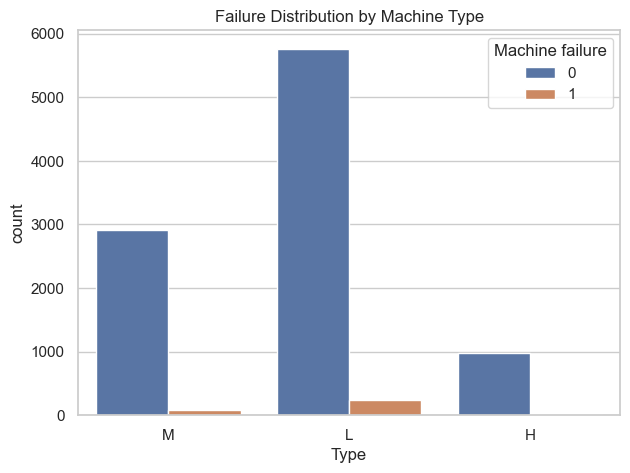

In [6]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="Type",
    hue="Machine failure"
)

plt.title("Failure Distribution by Machine Type")

plt.savefig(
    "../reports/figures/type_failure.png",
    bbox_inches="tight"
)

plt.show()

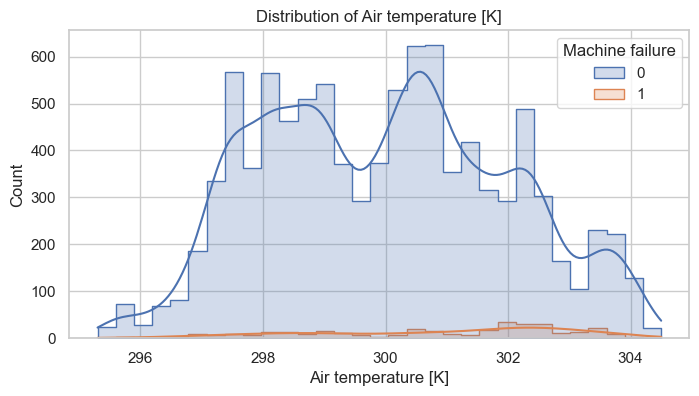

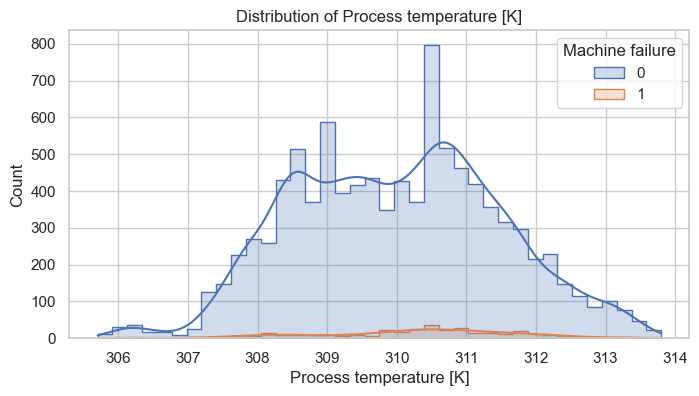

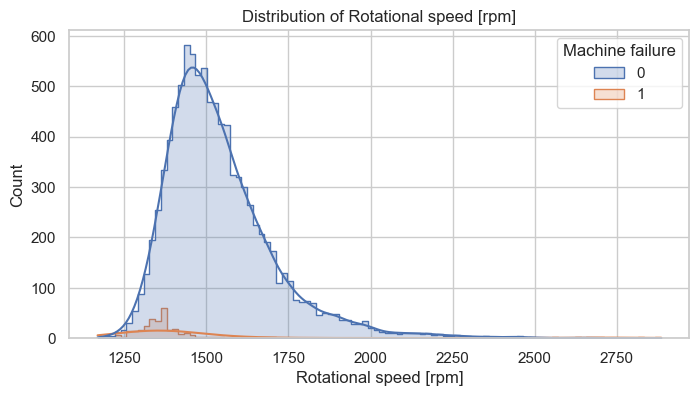

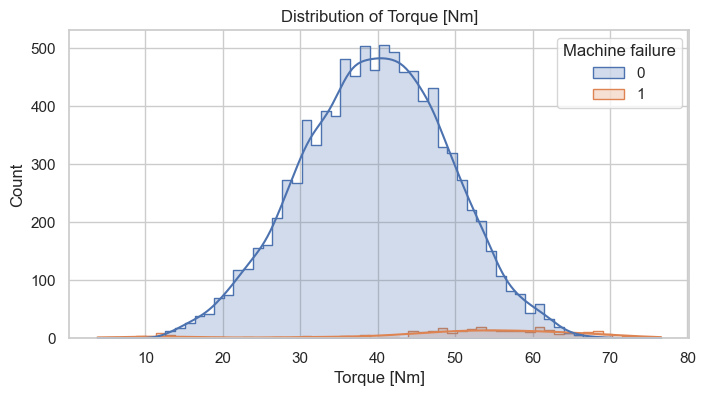

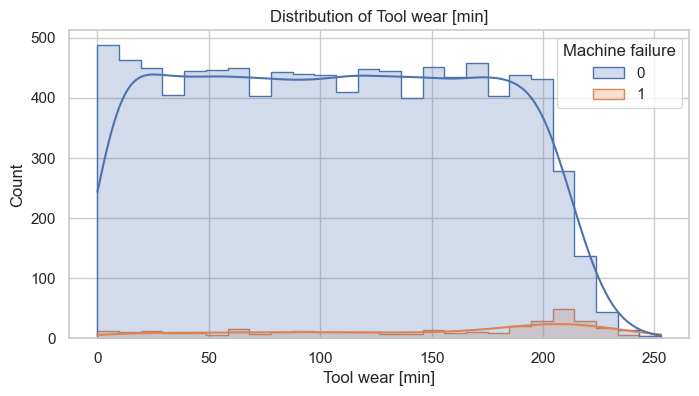

In [7]:
sensor_columns = [
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]"
]

for column in sensor_columns:

    plt.figure(figsize=(8, 4))

    sns.histplot(
        data=df,
        x=column,
        hue="Machine failure",
        kde=True,
        element="step"
    )

    plt.title(f"Distribution of {column}")

    plt.show()

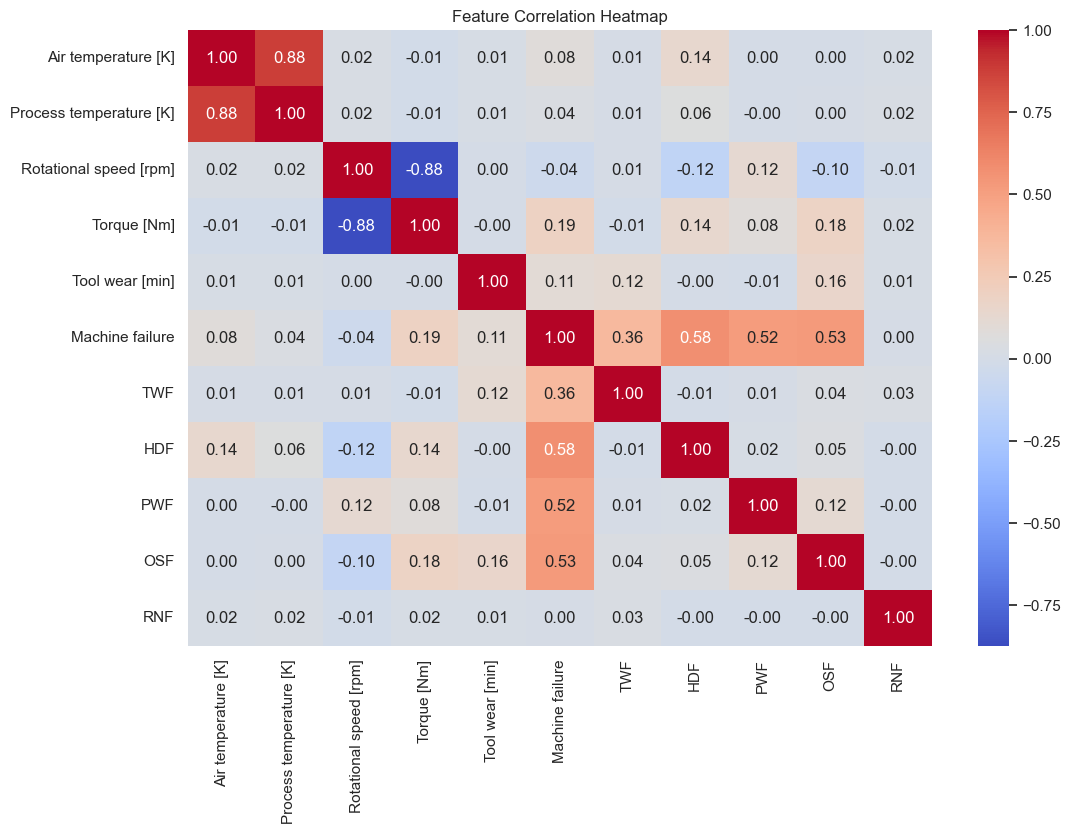

In [8]:
plt.figure(figsize=(12, 8))

numeric_df = df.select_dtypes(include="number")

sns.heatmap(
    numeric_df.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Feature Correlation Heatmap")

plt.savefig(
    "../reports/figures/correlation_heatmap.png",
    bbox_inches="tight"
)

plt.show()

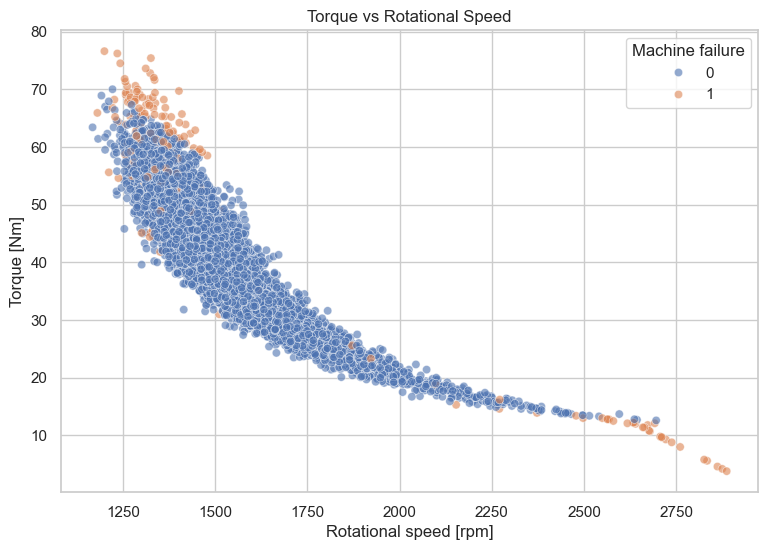

In [9]:
plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=df,
    x="Rotational speed [rpm]",
    y="Torque [Nm]",
    hue="Machine failure",
    alpha=0.6
)

plt.title("Torque vs Rotational Speed")

plt.savefig(
    "../reports/figures/torque_rpm.png",
    bbox_inches="tight"
)

plt.show()